In [ ]:
import pathlib
import tensorflow as tf
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


In [ ]:
!wget http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
!tar -xvzf speech_commands_v0.02.tar.gz


Streaming output truncated to the last 5000 lines.
./on/fc3ba625_nohash_0.wav
./on/db9d52d2_nohash_0.wav
./on/72242187_nohash_4.wav
./on/b0f5b16d_nohash_0.wav
./on/d9aa8c90_nohash_1.wav
./on/525eaa62_nohash_0.wav
./on/42e3f068_nohash_0.wav
./on/94d370bf_nohash_4.wav
./on/bf8d5617_nohash_0.wav
./on/e2b7d6d6_nohash_2.wav
./on/89ed36ab_nohash_0.wav
./on/30276d03_nohash_1.wav
./on/364c0853_nohash_0.wav
./on/7cbf645a_nohash_0.wav
./on/c98bbbd3_nohash_2.wav
./on/9a7c1f83_nohash_5.wav
./on/3589bc72_nohash_0.wav
./on/3ae5c04f_nohash_0.wav
./on/adc216c5_nohash_2.wav
./on/c50f55b8_nohash_15.wav
./on/324210dd_nohash_2.wav
./on/c120e80e_nohash_2.wav
./on/69086eb0_nohash_0.wav
./on/dce05676_nohash_1.wav
./on/435695e3_nohash_1.wav
./on/179a61b7_nohash_1.wav
./on/f5341341_nohash_0.wav
./on/91b03183_nohash_0.wav
./on/96d8bb6f_nohash_2.wav
./on/6a1908f8_nohash_0.wav
./on/6ace4fe1_nohash_1.wav
./on/84d1e469_nohash_1.wav
./on/ba676390_nohash_0.wav
./on/1dc86f91_nohash_4.wav
./on/3a929277_nohash_2.wav
./o

In [ ]:
DATASET_PATH = 'data/mini_speech_commands'

data_dir = pathlib.Path(DATASET_PATH)
if not data_dir.exists():
  tf.keras.utils.get_file(
      'mini_speech_commands.zip',
      origin="http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
      extract=True,
      cache_dir='.', cache_subdir='data')


182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
# !wget http://download.tensorflow.org/models/tflite/mini_speech_commands_v0.02.tar.gz
# !tar xvzf mini_speech_commands_v0.02.tar.gz
# !rm mini_speech_commands_v0.02.tar.gz

--2024-08-26 12:14:19--  http://download.tensorflow.org/models/tflite/mini_speech_commands_v0.02.tar.gz
Resolving download.tensorflow.org (download.tensorflow.org)... 142.250.101.207, 142.251.2.207, 142.250.141.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|142.250.101.207|:80... connected.
HTTP request sent, awaiting response... 403 Forbidden
2024-08-26 12:14:19 ERROR 403: Forbidden.



In [ ]:

# Set the path to the mini speech commands dataset
dataset_path = ""

# Define the labels for the dataset
labels = ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']

# Initialize lists to store the MFCC features and labels
X = []
y = []

# Iterate over the labels and extract MFCC features from the audio files
for label in labels:
  label_path = os.path.join(dataset_path, label)
  for filename in os.listdir(label_path):
    if filename.endswith(".wav"):
      filepath = os.path.join(label_path, filename)
      audio, sr = librosa.load(filepath, sr=16000)
      mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=16, win_length=int(sr*0.09), hop_length=int(sr*0.07))
      mel = librosa.power_to_db(mel,ref=np.max)
      X.append(mel.flatten())
      y.append(label)

mask = [X[i].shape == X[1].shape for i in range(len(X))]
X = np.array([X[i] for i in range(len(X)) if mask[i]])
y = np.array([y[i] for i in range(len(y)) if mask[i]])

#       # mfccs = mfcc(audio, samplerate=sr, numcep=16, nfilt=16, nfft=512)
#       # if mfccs.shape == (64, 32):
#       #   X.append(mfccs.flatten())
#       #   # X.append(np.mean(mfccs, axis=0))
#       #   y.append(label)

# Convert the lists to numpy arrays
X = np.array(X)
y = np.array(y)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15)#, random_state=42)

print(X.shape)

(28291, 240)


In [ ]:
# # Train a random forest classifier
# clf = RandomForestClassifier(n_estimators=150)
# clf.fit(X_train, y_train)

# # Make predictions on the test set

%%timeit -n 30 -r 5

# # Make predictions on the test set
y_pred = clf.predict(X_test)

# # Calculate the accuracy of the model
# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)


214 ms ± 38.7 ms per loop (mean ± std. dev. of 5 runs, 30 loops each)


In [ ]:
%%timeit -n 100 -r 5

tmel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=16, win_length=int(sr*0.09), hop_length=int(sr*0.07))
tmell = librosa.power_to_db(tmel,ref=np.max)
testt = tmell.flatten()
clf.predict(testt.reshape(1, -1))


17 ms ± 1.41 ms per loop (mean ± std. dev. of 5 runs, 100 loops each)


In [ ]:
70/len(y_pred)

0.024734982332155476

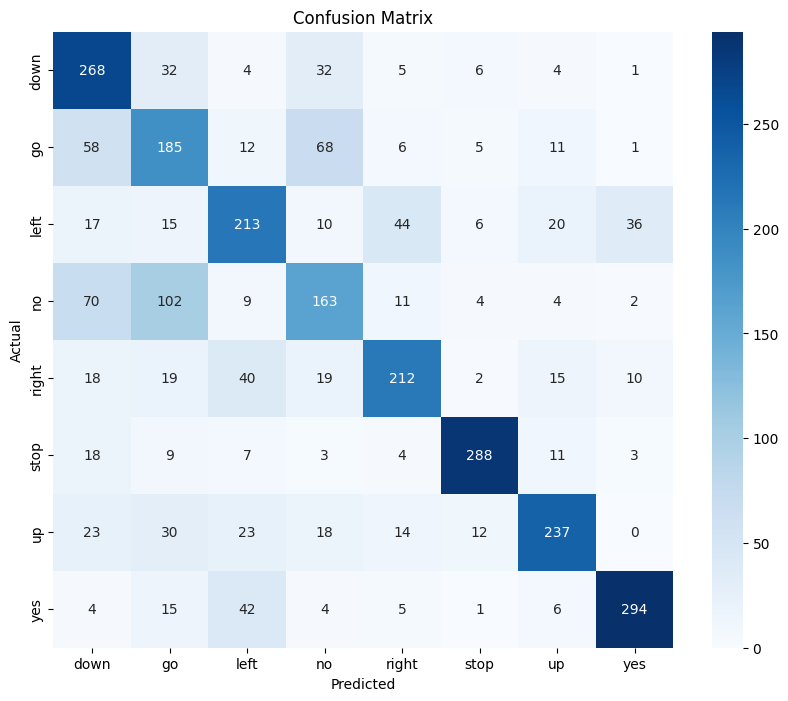

In [ ]:
# prompt: how can I get a confusion matrix for my random forest classifier?

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
# prompt: how can I get the size of the classifier if saved?

import pickle

# Save the classifier to a file
filename = 'random_forest_classifier.pkl'
pickle.dump(clf, open(filename, 'wb'))

# Get the size of the saved classifier file
size_bytes = os.path.getsize(filename)
size_kb = size_bytes / 1024
print(f"Size of the saved classifier: {size_kb:.2f} KB")


Size of the saved classifier: 5567.88 KB


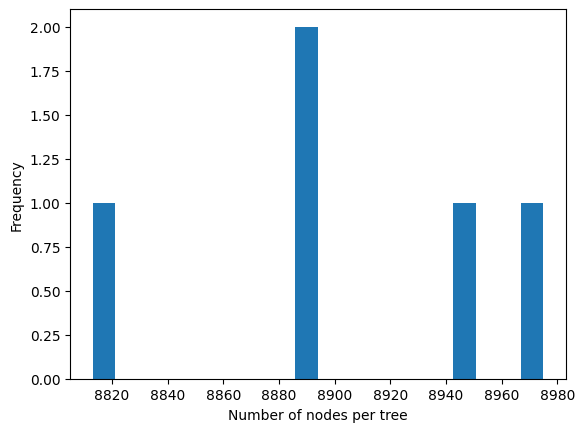

44517


In [ ]:
# n_trees = len(clf.estimators_)
# print("Number of trees in the forest:", n_trees)
# n_features = clf.n_features_in_
# n_features

n_nodes_per_tree = [estimator.tree_.node_count for estimator in clf.estimators_]
plt.hist(n_nodes_per_tree, bins=20)
plt.xlabel('Number of nodes per tree')
plt.ylabel('Frequency')
plt.show()
print(sum(n_nodes_per_tree))

In [ ]:
mel.shape

(20, 17)

In [ ]:
mel.shape

(24, 26)

In [ ]:
clf.predict(X_test)

array(['right', 'go', 'stop', ..., 'left', 'go', 'right'], dtype='<U5')

In [ ]:
shapes = [X[i].shape for i in range(len(X))]

In [ ]:
X_train[0]

array([ -6.34302358,  -5.26670001,  -3.13486533,   0.78553103,
        -5.31952952,   0.32129076, -12.60284313,  -3.15637653,
        -4.73786188,   2.21111328,  -5.43085693,  -2.67454903,
        -5.44353975])

In [ ]:
mfccs.shape

(99, 16)